# Week 12 — Visions

Run this notebook from the `week12` folder with the corpus installed as described in the README.

## Part 1 — Preparing the Sequences

Load and tokenize the first 1,010 bAbI lines. A sorted vocabulary gives each word a stable index.

In [1]:

def open_files():
    with open("data/qa1_train.txt", "r", encoding="utf-8") as f:
        raw_sentences = f.read().splitlines()

    # Inefficient: reads all 3000, but only returns 1010.
    # Claude suggests islice, for iterator slicing, to avoid this.
    return raw_sentences[:1010]

def tokenize_inputs(output_as_list = False):
    # capture the sentences (filters out newlines)
    raw_sentences = open_files()

    # Tokenize each sentence into a set of all words (lowercase) that appear in it,
    # excluding the first two characters.
    tokens = list(map(lambda s: set(s[2:].lower().split(" ")), raw_sentences))

    # If we want our final output as a list, make this a list instead so we can
    # reconstitute it later. Still generate the set: we use it to make vocab()
    # (though in this case we could just use tokens_list without much harm)
    if output_as_list==True:
        tokens_list = list(map(lambda s: list(s[1:].lower().split(" ")), raw_sentences))

    # list all words that appear (once each, because this is a set)

    # note: some words appear in multiple forms, e.g. "bathroom." and "\tbathroom\t1"
    # and various such. I asked, we're not supposed to funnel all those variations into
    # the same spot, we count them as distinct.
    vocab = sorted({word for sent in tokens for word in sent if len(word) > 0})


    # create dictionaries in both directions so we can convert word lists to indices
    # and indices to word lists. Only word2index is required, but index2word is really
    # useful for testing.
    word2index = {w: i for i, w in enumerate(vocab)}
    index2word = {i: w for i, w in enumerate(vocab)}

    # the list of all sentences' sets of words, each set in a random order
    # (note: because a lot of our numbers here are small, often it will be in
    # alphabetical order because hash(n)=n for small n and we sort the vocab)
    if output_as_list==False:
        input_dataset = [list({word2index[w] for w in sent if w in word2index}) for sent in tokens]
    # the list of all sentences' lists of words, each list in its original order
    if output_as_list==True:
        input_dataset = [[word2index[w] for w in sent if w in word2index] for sent in tokens_list]


    return raw_sentences, vocab, word2index, index2word, input_dataset


# given an array of strings, convert it into an array of the corresponding
# indices in vocab
def words2indices(sentence, word2index):
    return list(word2index[word] for word in sentence)

# given an array of indices, convert it into an array of the corresponding
# strings in vocab
def indices2words(sentence, index2word):
    return list(index2word[index] for index in sentence)




if __name__ == "__main__":
    # tokenize everything
    raw_sentences, vocab, word2index, index2word, input_dataset = tokenize_inputs(output_as_list=False)
    _, _, _, _, input_dataset_list = tokenize_inputs(output_as_list=True)

    # print the first four sentences and various forms of them for verification
    for i, term in zip(range(7), ["First", "Second", "Third", "Fourth", "Fifth", "Sixth", "Seventh"]):
        print(f"{term} raw sentence is:\n{raw_sentences[i]}\nAfter processing:\n")
        print(f"Corresponding indices as a set are {input_dataset[i]}, which correspond to the words {indices2words(input_dataset[i], index2word)}")    
        print(f"Corresponding indices as a list are {input_dataset_list[i]}, which correspond to the words {indices2words(input_dataset_list[i], index2word)}\n\n")    


First raw sentence is:
1 Mary moved to the bathroom.
After processing:

Corresponding indices as a set are [71, 73, 77, 78, 60], which correspond to the words ['mary', 'moved', 'the', 'to', 'bathroom.']
Corresponding indices as a list are [71, 73, 78, 77, 60], which correspond to the words ['mary', 'moved', 'to', 'the', 'bathroom.']


Second raw sentence is:
2 John went to the hallway.
After processing:

Corresponding indices as a set are [65, 67, 77, 78, 80], which correspond to the words ['hallway.', 'john', 'the', 'to', 'went']
Corresponding indices as a list are [67, 80, 78, 77, 65], which correspond to the words ['john', 'went', 'to', 'the', 'hallway.']


Third raw sentence is:
3 Where is Mary? 	bathroom	1
After processing:

Corresponding indices as a set are [0, 81, 66, 72], which correspond to the words ['\tbathroom\t1', 'where', 'is', 'mary?']
Corresponding indices as a list are [81, 66, 72, 0], which correspond to the words ['where', 'is', 'mary?', '\tbathroom\t1']


Fourth ra

## Part 2 — The Forward Pass

Carry the hidden state through a sentence and predict each next word. Perplexity measures how well those predictions fit the sentence.

In [2]:
import numpy as np
from preprocess import tokenize_inputs, words2indices


# From an array of relative log-probs, calculates the actual probabilities
def softmax(x):
    # first, without losing relative magnitudes, subtract the largest.
    # This means the largest x is 0, so we can't get any values larger than 1,
    # so we can't have anything larger than a float can be
    x -= np.max(x)

    # exponentiate
    x = np.exp(x)
    # divide by the total, bringing our final total to 1
    x /= np.sum(x)
    # return that array of probabilities
    return x

# Given the list of all words (except the first, see below for external 
# implementation), our initial bias term, our decoder, our adjustment 
# to past hidden states and our embedding, predict each token in a sequence.

# notably, this intentionally departs from assignment spec by having
# multiple parameters rather than just using global variables, and by
# returning two separate index-matched arrays for hiddens and preds.

# Note: layers[k]['pred'] is the guess for sent[k-1], made after seeing
# sent[:k-1], everything up until that point. That is, layers[3]['pred']
# is the guess for what word will be sent[2], after feeding it
# start*recurrence*recurrence, the embedding*recurrence of sent[0] 
# and the embedding of sent[1].
#
# But the sentences we're feeding our predict() have the first
# word lopped off for no reason (see below, in main() and later in train.py),
# so layers[k]['pred'] will be the guess for original_sentence[k], but without the 
# information of the first word. E.g. layers[3]['pred'] is the guess for
# original_sentence[3], with only start*recurrence*recurrence*recurrence, 
# the embedding*recurrence of original_sentence[1] and the embedding of 
# original_sentence[2] and not the embedding*recurrence*recurrence of 
# original_sentence[0] (because we lopped it off).
def predict(sent, start, decoder, recurrent, embed):
    layers = [{'hidden': start}]
    loss = 0.0

    # for each word, sequentially:
    for t in range(len(sent)):
        # our current hidden layer is the last
        # entry in hiddens
        h_prev = layers[-1]['hidden']
        # our prediction is the softmax of our
        # hidden layer times the decoder
        pred = softmax(h_prev.dot(decoder))
        # our loss is the log-difference between
        # our actual chance (ln 1 = 0) and our
        # predicted chance (e.g. ln 0.37 = -1,
        # total loss = 0 - -1 = 1). No need to
        # absolute value this, because softmax
        # prevents ever predicting more than 1
        loss += -np.log(pred[sent[t]])

        # our hidden layer for next time will be the
        # current hidden layer * recurrence plus the
        # embedding of the real word that we just
        # tried to predict
        h_new = h_prev.dot(recurrent) + embed[sent[t]]

        # stick 'em on! See comments above predict()
        # for where what goes
        layers.append({'pred': pred, 'hidden': h_new})
    return layers, loss

# perplexity = e^(average loss)
def perplexity(loss, length):
    return np.exp(loss/length)


if __name__ == "__main__":
    # various variables, tokenization
    np.random.seed(1)
    embed_size = 10
    raw_sentences, vocab, word2index, index2word, input_dataset = tokenize_inputs(output_as_list = True)
    V = len(vocab)
    embed = (np.random.rand(V, embed_size) - 0.5) * 0.1
    recurrent = np.eye(embed_size)
    start = np.zeros(embed_size)
    decoder = (np.random.rand(embed_size, V) - 0.5) * 0.1
    one_hot = np.eye(V)
    # why, oh why are we starting from the second word? Claude and I concluded that this
    # was somewhat unhinged and didn't have any coherent reason, and might be a duplication
    # of the first-number removal in the preprocessing, even after checking Trask's code
    # on GitHub. 
    # 
    # The assignment spec is clear, we are to use this, it gets the same
    # perplexity for the same seed as Dr. Faith does. It calls it "Trask's convention", 
    # but we can find no reason for this convention.
    _, loss = predict(input_dataset[0][1:], start, decoder, recurrent, embed)
    print(perplexity(loss, len(input_dataset[0][1:])))

81.94009027613271


## Part 3 — Backpropagation Through Time

Pass prediction errors backward through the sequence and update the weights. This lets later errors affect the weights used at earlier steps.

In [3]:
import numpy as np
from preprocess import tokenize_inputs, words2indices
from rnn_forward import predict, perplexity

def bptt(sent, layers, weights, one_hot):
    """Backward Propagation Through Time
    Parameters:
        sent (in): sentence as a word2index mapping used for getting a target index
        layers (in-out): list of layers, which are a dictionary with pred (optional) and a hidden state, soon to have an output_delta and a hidden_delta
        weights (in): RNNW object for accessing decoder and recurrent weight matrices
        one_hot (in): used for calculating output deltas
    """
    # Layer 0 doesn't have a pred, so leave it out of the loop
    # The -1:0:-1 slice goes in reverse iterating through the range
    # [last..0) -- the last layer down to but not including the first layer
    for i, layer in enumerate(layers[-1:0:-1]):
        # i starts from 0, so we need to calculate the distance from the end
        layer_idx = len(layers) - i - 1
        target = sent[layer_idx - 1]
        layer['output_delta'] = layer['pred'] - one_hot[target]
        new_hidden_delta = layer['output_delta'].dot(weights.decoder.T)

        if layer_idx == len(layers) - 1:
            layer['hidden_delta'] = new_hidden_delta
        else:
            layer['hidden_delta'] = new_hidden_delta + layers[layer_idx + 1]['hidden_delta'].dot(weights.recurrent.T)

    # Get the hidden_delta for layer 0 so the walk is complete; this must necessarily
    # be after the loop so layer 1's hidden_delta exists
    layers[0]['hidden_delta'] = layers[1]['hidden_delta'].dot(weights.recurrent.T)

    return layers # just in case in-out parameters don't work...

# Preconditions:
# - My weights class won't be used by others
# - The random seed is already set
def train_step(sent, start, decoder, recurrent, embed, alpha, one_hot):
    # Predict
    layers, loss = predict(sent, start, decoder, recurrent, embed)

    weights = pack(embed, recurrent, start, decoder) # pack the weights into my class

    # Compare
    layers = bptt(sent, layers, weights, one_hot)

    # Learn
    weights.update(sent, layers, alpha)

    return perplexity(loss, len(sent)), weights.unmarshal()

def pack(embed, recurrent, start, decoder):
    """Pack weights defined externally
    (beyond this file) into the class"""
    return RNNW().marshal(embed, recurrent, start, decoder)

# probably overengineered, but here's a class for weights.
# it's essentially a struct for each of the four weight
# tensors with (un)marshal methods and the update method.
class RNNW:
    """RNN Weights, namely start, embed, recurrent, and decoder"""
    def __init__(self, embed_size = None, vocab_size = None):
        self.embed, self.recurrent, self.start, self.decoder = None, None, None, None

        if embed_size is not None and vocab_size is not None:
            self.embed = (np.random.rand(vocab_size, embed_size) - 0.5) * 0.1
            self.recurrent = np.eye(embed_size)
            self.start = np.zeros(embed_size)
            self.decoder = (np.random.rand(embed_size, vocab_size) - 0.5) * 0.1

    def marshal(self, embed, recurrent, start, decoder):
        self.embed = embed
        self.recurrent = recurrent
        self.start = start
        self.decoder = decoder
        return self

    def unmarshal(self):
        return self.embed, self.recurrent, self.start, self.decoder

    def update(self, sent, layers, alpha):
        """Update the weights given the deltas
        baked into each layer; we also have the
        sentence for getting the length and alpha"""
        scalar = alpha / len(sent)
        self.start -= layers[1]['hidden_delta'] * scalar
        for layer_idx, layer in enumerate(layers[1:]):
            self.decoder -= np.outer(layers[layer_idx]['hidden'],
                                     layer['output_delta']) * scalar
            if layer_idx + 2 < len(layers): # last state makes no guess
                grad_h = layers[layer_idx + 2]['hidden_delta']
                self.embed[sent[layer_idx]] -= grad_h * scalar
                self.recurrent -= np.outer(layers[layer_idx]['hidden'],
                                           grad_h) * scalar

if __name__ == "__main__":
    np.random.seed(1)
    vocab, word2index, _, data = tokenize_inputs()[1:]
    weights = RNNW(embed_size = 10, vocab_size = len(vocab))
    sent = data[0][1:]
    one_hot = np.eye(len(vocab))
    layers = predict(sent, weights.start, weights.decoder, weights.recurrent, weights.embed)[0]
    layers = bptt(sent, layers, weights, one_hot)

    # read the deltas
    # a random k
    k = np.random.randint(2, len(layers))
    print(f"-- Layer {k} --")
    print(f"Pred: {layers[k]['pred']}")
    print(f"Hidden (stored in previous state): {layers[k-1]['hidden']}")
    print(f"Hidden delta (stored in next state): {layers[k+1]['hidden_delta']}")
    print()

    # exploring start
    print(f"-- Start (Layer 0) --")
    print(f"Pred (should be `start`): {layers[0]['hidden']}")
    print(f"Hidden delta (in layer 1): {layers[1]['hidden_delta']}")
    print()

    # sent[i]'s effect on layers after it
    # a random i
    i = np.random.randint(len(sent))
    print(f"-- sent[{i}]'s effects on later layers --")
    print(f"sent[{i}]: {sent[i]}")
    print(f"Layer {i+1}'s state: {layers[i+1]['hidden']}")
    print(f"sent[{i}]'s gradient (found in layer {i+2}): {layers[i+2]['hidden_delta']}")
    print()


-- Layer 2 --
Pred: [0.01220672 0.01216453 0.01218379 0.01218944 0.01222055 0.01218585
 0.01225425 0.01222137 0.01217988 0.01220055 0.01224388 0.01220257
 0.01211942 0.01217343 0.01222492 0.01214309 0.01219969 0.01217784
 0.01223128 0.01220747 0.01222798 0.01220632 0.01217888 0.01220046
 0.01215505 0.01218569 0.01219735 0.01222426 0.01217631 0.01218128
 0.01217464 0.01218753 0.01217399 0.01217156 0.0121975  0.01223397
 0.01222542 0.01218652 0.01216846 0.01225721 0.01215355 0.01209503
 0.01225485 0.01218268 0.01222297 0.012208   0.01222593 0.01219061
 0.01220524 0.01218535 0.01222873 0.01220504 0.01219701 0.01219065
 0.01223342 0.01226299 0.01216149 0.01224342 0.01218456 0.01217754
 0.01216869 0.01215421 0.01217012 0.01221506 0.01216136 0.01221355
 0.01216577 0.01216985 0.01221603 0.0121611  0.01221647 0.01218012
 0.01217106 0.01220067 0.01223494 0.01219883 0.0121814  0.01218658
 0.01223865 0.01218929 0.01218813 0.01216812]
Hidden (stored in previous state): [ 0.001786   -0.03055342  0.

## Part 4 — Training to Convergence

Train for 30,000 iterations on the first 1,000 lines and save the weights and perplexity log. Keeping the next ten lines out of the loop gives Part 5 a separate set of examples.

In [4]:
import numpy as np
import csv
import time

from preprocess import tokenize_inputs
from rnn_bptt import RNNW, train_step
from rnn_forward import predict

def train(alpha, iter, TRAIN_N, seed, sentances, vocab, word2indecies, indecies2words, tokens, verbose = False):
    # Set random
    np.random.seed(seed)
    one_hot = np.eye(len(vocab))

    # build RNN weights class
    weights = RNNW(embed_size = 10, vocab_size = len(vocab))

    # for writing out to CSV
    perplexity_log = []
    
    for it in range(iter):
        sent = tokens[it % TRAIN_N][1:]
        layers, loss = predict(sent, weights.start, weights.decoder, weights.recurrent, weights.embed)

        # ---- back propagate (BPTT in Code, 3 of 3) ---- fills in the deltas
        # ---- update weights (The Weight Updates) ---- subtracts them

        perplexity, _ = train_step(sent, weights.start, weights.decoder, weights.recurrent, weights.embed, alpha, one_hot)

        if it % 1000 == 0:
            perplexity_log.append((it, perplexity))
            if verbose:
                print(f"Iteration {it}:\tPerplexity: {perplexity}")

    # Save csv
    with open("perplexity_log.csv", "w", newline = "") as f:
        writer = csv.writer(f)
        writer.writerow(["iteration", "perplexity"])
        writer.writerow(perplexity_log)

    # Save weights
    np.savez("trained_weights.npz", start = weights.start, decoder = weights.decoder, recurrent = weights.recurrent, embed = weights.embed)

    return perplexity_log


if __name__ == "__main__":
    sentances, vocab, word2index, index2word, tokens = tokenize_inputs(output_as_list = True)

    train(0.001, 30000, 1000, 1, sentances, vocab, word2index, index2word, tokens, verbose = True)



Iteration 0:	Perplexity: 81.94009027613271
Iteration 1000:	Perplexity: 81.82180215790378
Iteration 2000:	Perplexity: 81.66450153901582
Iteration 3000:	Perplexity: 81.41753122251701
Iteration 4000:	Perplexity: 80.99398846096734
Iteration 5000:	Perplexity: 80.22805702313086
Iteration 6000:	Perplexity: 78.77535930022067
Iteration 7000:	Perplexity: 75.83529133513223
Iteration 8000:	Perplexity: 69.19924667951561
Iteration 9000:	Perplexity: 51.91103974043919
Iteration 10000:	Perplexity: 32.70661578955616
Iteration 11000:	Perplexity: 24.96255544132746
Iteration 12000:	Perplexity: 19.50317014355903
Iteration 13000:	Perplexity: 15.787364974412316
Iteration 14000:	Perplexity: 13.106106169966276
Iteration 15000:	Perplexity: 10.72736970008275
Iteration 16000:	Perplexity: 8.946068720881533
Iteration 17000:	Perplexity: 7.79715564894633
Iteration 18000:	Perplexity: 7.053009622902128
Iteration 19000:	Perplexity: 6.530422450166163
Iteration 20000:	Perplexity: 6.13436780870996
Iteration 21000:	Perplexit

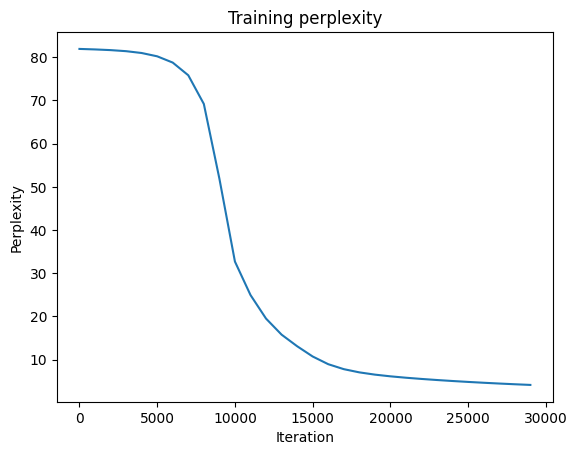

In [5]:
import re
from pathlib import Path
import matplotlib.pyplot as plt

# The training script writes the logged pairs as tuple strings in the CSV.
log = Path("perplexity_log.csv").read_text(encoding="utf-8")
pairs = re.findall(r"\((\d+), (?:np\.float64\()?([0-9.eE+-]+)\)\)?", log)
iterations, perplexities = zip(*[(int(step), float(value)) for step, value in pairs])
plt.plot(iterations, perplexities)
plt.xlabel("Iteration")
plt.ylabel("Perplexity")
plt.title("Training perplexity")
plt.show()

## Part 5 — Reading a Sentence

Compare the true next word with the model’s top prediction on three statements past the training cutoff. The tables show where a familiar sentence pattern helps.

In [6]:
# Set the script location for the verbatim Part 5 code below.
__file__ = "generate.py"

In [7]:
"""Show next-word predictions on three statements past the training cut."""

from pathlib import Path

import numpy as np

from preprocess import indices2words, tokenize_inputs
from rnn_forward import predict


def next_word_tables():
    """Return Markdown tables using the vocabulary and weights from training."""
    raw_lines, _, _, index2word, tokens = tokenize_inputs(output_as_list=True)
    statement_indices = [
        index for index, line in enumerate(raw_lines[1000:1010], start=1000)
        if line.endswith(".") and "?" not in line
    ][:3]
    if len(statement_indices) != 3:
        raise ValueError("Expected three statements at corpus indices 1000 through 1009.")

    tables = []
    weights_path = Path(__file__).resolve().with_name("trained_weights.npz")
    with np.load(weights_path) as saved:
        weights = {name: saved[name] for name in ("start", "decoder", "recurrent", "embed")}

    for index in statement_indices:
        sent = tokens[index][1:]
        words = indices2words(sent, index2word)
        layers, _ = predict(sent, **weights)
        original = raw_lines[index].split(maxsplit=1)[1]
        rows = [
            f"**Corpus index {index}** ({original})",
            "",
            "| Context | True next word | Network prediction |",
            "| --- | --- | --- |",
        ]
        # Layer 1 predicts from the start state, before seeing any words.
        for position in range(1, len(words)):
            context = " ".join(words[:position])
            prediction = index2word[layers[position + 1]["pred"].argmax()]
            rows.append(f"| {context} | {words[position]} | {prediction} |")
        tables.append("\n".join(rows))

    return "\n\n".join(tables)


if __name__ == "__main__":
    print(next_word_tables())


**Corpus index 1000** (Daniel moved to the kitchen.)

| Context | True next word | Network prediction |
| --- | --- | --- |
| moved | to | to |
| moved to | the | the |
| moved to the | kitchen. | bedroom. |

**Corpus index 1002** (Sandra went back to the bedroom.)

| Context | True next word | Network prediction |
| --- | --- | --- |
| went | back | to |
| went back | to | the |
| went back to | the | the |
| went back to the | bedroom. | bedroom. |

**Corpus index 1003** (Sandra went to the hallway.)

| Context | True next word | Network prediction |
| --- | --- | --- |
| went | to | to |
| went to | the | the |
| went to the | hallway. | bedroom. |


On lines 1000 and 1003 the model correctly predicts `to` and `the`. It expects `to` immediately after `went`, so it misses `back` on line 1002. It guesses `bedroom.` for all three destinations and gets one right. The prefix does not tell the model which room the person entered.

## Part 6 — Tests

Check tokenization, softmax, the forward pass, loss reduction, and the two contributions to the hidden delta.

In [8]:
import numpy as np
from preprocess import tokenize_inputs
from rnn_forward import softmax, predict, perplexity
from rnn_bptt import RNNW, bptt, train_step

def test_preprocess():
    _, vocab, word2index = tokenize_inputs()[:3]
    assert len(vocab) == 82, f"Vocab length on first 1010 lines should be 82, got {len(vocab)}"
    for word in ["garden.", "john", "kitchen."]:
        assert vocab[word2index[word]] == word, f"word2index must round-trip on {word}, got {vocab[word2index[word]]}"

def test_softmax():
    for size in [3, 6, 14, 23]:
        x = np.random.randn(size)
        assert np.abs(np.sum(softmax(x)) - 1) <= 1e-9, f"Sum of any softmaxed vector must be within 1e-9 of 1, got {np.sum(softmax(x))}"
    zs = np.zeros(np.random.randint(10))
    softzs = softmax(zs)
    assert np.all(softz == softzs[0] for softz in softzs), f"Entries of a softmaxed zero vector are uniform, got {softzs}"

def test_forward_shape():
    np.random.seed(1)
    vocab, _, _, tokens = tokenize_inputs()[1:]
    weights = RNNW(10, len(vocab))
    sent = tokens[0][1:]
    layers, loss = predict(sent,
                           weights.start,
                           weights.decoder,
                           weights.recurrent,
                           weights.embed)
    assert len(layers) == len(sent) + 1, f"Returned layers must equal len(sent) + 1 ({len(sent) + 1}), got {len(layers)}"
    assert 80 <= perplexity(loss, len(sent)) <= 84, f"Perplexity must be in the range [80, 84], got {perplexity(loss, len(sent))}"

# when we get a training loop from part 4 i think we'll replace mine with that one
def test_training_loss():
    np.random.seed(1)
    vocab, _, _, data = tokenize_inputs()[1:]
    sent = data[0][1:]
    S, V = len(sent), len(vocab)
    alpha, one_hot = 0.005, np.eye(V)
    weights = RNNW(3, V)
    initial_perplexity, _ = train_step(
        sent, weights.start, weights.decoder, weights.recurrent, weights.embed, alpha, one_hot
    )
    for _ in range(98):
        train_step(
            sent, weights.start, weights.decoder, weights.recurrent, weights.embed, alpha, one_hot
        )
    final_perplexity, _ = train_step(
        sent, weights.start, weights.decoder, weights.recurrent, weights.embed, alpha, one_hot
    )
    assert final_perplexity < initial_perplexity, f"Perplexity must decrease over 100 train steps, got final_perplexity={final_perplexity}, initial_perplexity={initial_perplexity}"

def test_hidden_delta_sum():
    np.random.seed(1)
    vocab, _, _, data = tokenize_inputs()[1:]
    sent = [sent for sent in data if 3 <= len(sent) <= 7][0]
    one_hot = np.eye(len(vocab))
    weights = RNNW(3, len(vocab))
    layers, _ = predict(sent, weights.start, weights.decoder, weights.recurrent, weights.embed)
    layers = bptt(sent, layers, weights, one_hot)
    i = np.random.randint(1, len(layers) - 2)
    layer = layers[i]
    d_h, d_o = layer['hidden_delta'], layer['output_delta']
    h_r = layers[i+1]['hidden_delta'].dot(weights.recurrent.T)
    h_d = d_o.dot(weights.decoder.T)
    assert np.all(d_h - h_r == h_d), "Hidden delta must differ from output_delta.dot(decoder.T) alone"

if __name__ == "__main__":
    tests = [name for name in dir() if name.startswith("test_")]
    for test_name in sorted(tests):
        test_func = globals()[test_name]
        try:
            test_func()
            print(f" PASS: {test_name}")
        except AssertionError as e:
            print(f" FAIL (AssertionError): {test_name} -- {e}")


 PASS: test_forward_shape
 PASS: test_hidden_delta_sum
 PASS: test_preprocess
 PASS: test_softmax
 PASS: test_training_loss


### Run summary

The last logged perplexity was 4.15 at iteration 29,000. The 30,000-iteration run took about 3.2 seconds on a Windows x64 CPU.

## Part 7 — Reading the Holocron

### Holocron — Reading

On line 1003, the model sees `went to` and correctly predicts `the`. That line was past the training cutoff, but the same statement appeared earlier in the corpus. The prediction is consistent with learning a familiar template, and this example alone cannot tell us whether the model would handle a sentence outside that template. Its next guess, `bedroom.`, misses the actual destination, `hallway.`. Both rooms fit the words the model has seen so far.

I would hold out entire motion phrases before training and build a test set around those phrases. The test sentences would use familiar words in new combinations, and I would check for duplicates against the training set. I would also test pairs of prefixes where one early word changes what can reasonably follow. That would tell me whether the model uses the earlier clue or keeps making the same guess.

Korrith’s warning makes me think about how easily a fluent answer can pass for a grounded one. I would check for confident room guesses when the prefix leaves the destination open. A model that fills in a likely room could turn a guess into a supposed fact if someone used its output to report where a person went.